In [3]:
# ============================================
# LAB #7 - STUDENT PERFORMANCE PREDICTOR
# ============================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [7]:
from google.colab import files

uploaded = files.upload()

Saving student+performance (3).zip to student+performance (3).zip


In [9]:
import zipfile

zip_file = "student+performance (3).zip"

with zipfile.ZipFile(zip_file, "r") as z:
    print("FILES INSIDE ZIP:")
    for name in z.namelist():
        print(name)

FILES INSIDE ZIP:
.student.zip_old
student.zip


In [10]:
import zipfile
import pandas as pd
import os

# Open the uploaded outer ZIP
outer_zip = "student+performance (3).zip"

with zipfile.ZipFile(outer_zip, "r") as z:
    # Extract the inner student.zip
    z.extract("student.zip", "student_data")

# Open inner ZIP
inner_zip = "student_data/student.zip"

with zipfile.ZipFile(inner_zip, "r") as z:
    print("Inside student.zip:")
    for name in z.namelist():
        print(name)

    # Find student-mat.csv
    csv_file = [name for name in z.namelist()
                if name.lower().endswith("student-mat.csv")][0]

    # Read CSV directly from ZIP
    with z.open(csv_file) as f:
        df = pd.read_csv(f, sep=";")

print("\n✅ DATASET LOADED!")
print("Shape:", df.shape)

display(df.head())

Inside student.zip:
student-mat.csv
student-por.csv
student-merge.R
student.txt

✅ DATASET LOADED!
Shape: (395, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [11]:
# CELL 3 - Dataset Check

print("Dataset Shape:", df.shape)

print("\nFirst 5 Rows:")
display(df.head())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nTotal Missing Values:",
      df.isnull().sum().sum())

Dataset Shape: (395, 33)

First 5 Rows:


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-null    object
 11  guardian    395 non-null    object
 12  traveltime  395 non-null    int64 
 13  studytime   395 non-null    int64 
 14  failures    395 non-null    int64 
 15  schoolsup   395 non-null    object
 16  famsup      395 non-null    object
 17  paid        395 non-null    object
 18  activities  395 non-null    object
 19  nursery     395 non-null    

In [12]:
# CELL 4 - Preprocessing

import numpy as np

# Handle missing numerical values
numeric_columns = df.select_dtypes(include=np.number).columns

for column in numeric_columns:
    df[column] = df[column].fillna(df[column].median())

# Handle missing categorical values
categorical_columns = df.select_dtypes(exclude=np.number).columns

for column in categorical_columns:
    df[column] = df[column].fillna(df[column].mode()[0])

# Create Pass/Fail column
# G3 >= 10 = Pass
# G3 < 10 = Fail

df["Pass_Fail"] = np.where(df["G3"] >= 10, 1, 0)

print("Preprocessing completed successfully!")

print("\nMissing values after preprocessing:")
print(df.isnull().sum().sum())

print("\nPass/Fail Distribution:")
print(df["Pass_Fail"].value_counts())

display(df[["G3", "Pass_Fail"]].head(10))

Preprocessing completed successfully!

Missing values after preprocessing:
0

Pass/Fail Distribution:
Pass_Fail
1    265
0    130
Name: count, dtype: int64


,G3,Pass_Fail
0,6,0
1,6,0
2,10,1
3,15,1
4,10,1
5,15,1
6,11,1
7,6,0
8,19,1
9,15,1


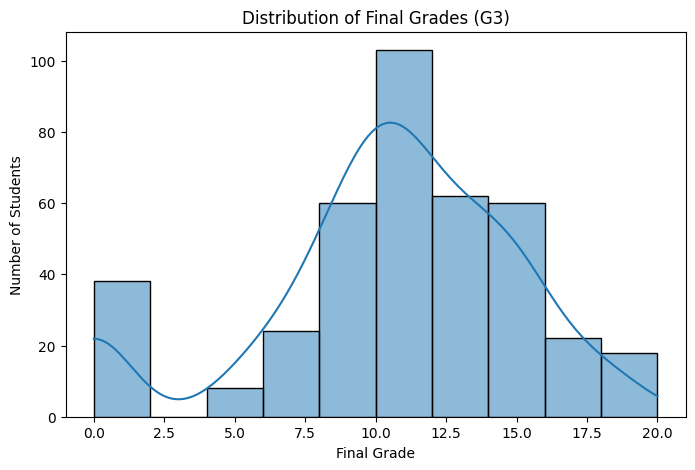

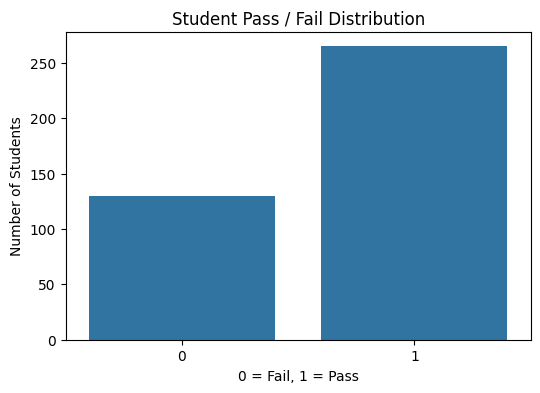

In [13]:
# CELL 5 - Visualization

import matplotlib.pyplot as plt
import seaborn as sns

# Final Grade Distribution
plt.figure(figsize=(8, 5))
sns.histplot(df["G3"], bins=10, kde=True)

plt.title("Distribution of Final Grades (G3)")
plt.xlabel("Final Grade")
plt.ylabel("Number of Students")
plt.show()


# Pass / Fail Distribution
plt.figure(figsize=(6, 4))
sns.countplot(x="Pass_Fail", data=df)

plt.title("Student Pass / Fail Distribution")
plt.xlabel("0 = Fail, 1 = Pass")
plt.ylabel("Number of Students")
plt.show()

In [14]:
# CELL 6 - Features and Train/Test Split

from sklearn.model_selection import train_test_split

# Features used to predict student performance
features = [
    "studytime",
    "failures",
    "absences",
    "G1",
    "G2",
    "age",
    "Medu",
    "Fedu",
    "goout",
    "health"
]

# Input features
X = df[features]

# Target for Linear Regression
y_regression = df["G3"]

# Target for Classification
y_classification = df["Pass_Fail"]

print("Features:")
print(features)

print("\nFeature data shape:", X.shape)

# Split data for Regression
X_train, X_test, y_train_reg, y_test_reg = train_test_split(
    X,
    y_regression,
    test_size=0.20,
    random_state=42
)

# Split data for Classification
X_train_cls, X_test_cls, y_train_cls, y_test_cls = train_test_split(
    X,
    y_classification,
    test_size=0.20,
    random_state=42,
    stratify=y_classification
)

print("\nRegression Training data:", X_train.shape)
print("Regression Testing data:", X_test.shape)

print("\nClassification Training data:", X_train_cls.shape)
print("Classification Testing data:", X_test_cls.shape)

Features:
['studytime', 'failures', 'absences', 'G1', 'G2', 'age', 'Medu', 'Fedu', 'goout', 'health']

Feature data shape: (395, 10)

Regression Training data: (316, 10)
Regression Testing data: (79, 10)

Classification Training data: (316, 10)
Classification Testing data: (79, 10)


In [15]:
# CELL 7 - Feature Scaling

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# Scale regression data
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Scale classification data
X_train_cls_scaled = scaler.fit_transform(X_train_cls)
X_test_cls_scaled = scaler.transform(X_test_cls)

print("Feature scaling completed successfully!")

print("\nScaled Training Data Shape:", X_train_scaled.shape)
print("Scaled Testing Data Shape:", X_test_scaled.shape)

Feature scaling completed successfully!

Scaled Training Data Shape: (316, 10)
Scaled Testing Data Shape: (79, 10)


In [16]:
# CELL 8 - Linear Regression
# Predicting Final Grade (G3)

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Create Linear Regression model
linear_model = LinearRegression()

# Train the model
linear_model.fit(X_train_scaled, y_train_reg)

# Make predictions
y_pred_reg = linear_model.predict(X_test_scaled)

# Calculate evaluation metrics
mae = mean_absolute_error(y_test_reg, y_pred_reg)
mse = mean_squared_error(y_test_reg, y_pred_reg)
rmse = np.sqrt(mse)
r2 = r2_score(y_test_reg, y_pred_reg)

print("===== LINEAR REGRESSION RESULTS =====")
print("MAE  :", round(mae, 3))
print("MSE  :", round(mse, 3))
print("RMSE :", round(rmse, 3))
print("R²   :", round(r2, 3))

===== LINEAR REGRESSION RESULTS =====
MAE  : 1.38
MSE  : 4.677
RMSE : 2.163
R²   : 0.772


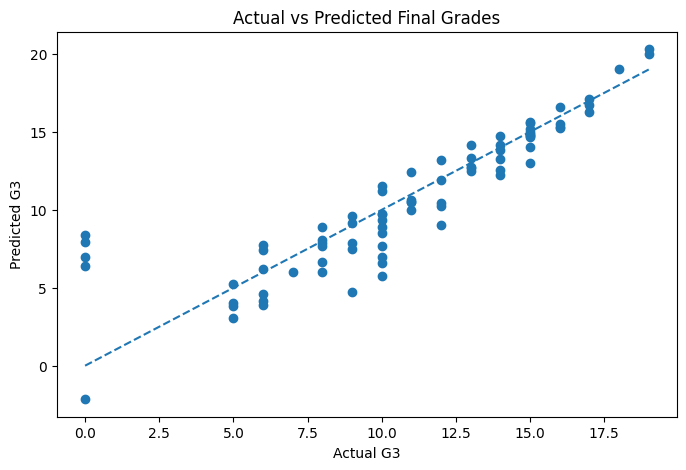

In [17]:
# CELL 9 - Actual vs Predicted

plt.figure(figsize=(8, 5))

plt.scatter(y_test_reg, y_pred_reg)

plt.xlabel("Actual G3")
plt.ylabel("Predicted G3")
plt.title("Actual vs Predicted Final Grades")

# Perfect prediction reference line
plt.plot(
    [y_test_reg.min(), y_test_reg.max()],
    [y_test_reg.min(), y_test_reg.max()],
    linestyle="--"
)

plt.show()

In [18]:
# CELL 10 - Logistic Regression

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Create Logistic Regression model
logistic_model = LogisticRegression(max_iter=1000)

# Train the model
logistic_model.fit(X_train_cls_scaled, y_train_cls)

# Make predictions
y_pred_log = logistic_model.predict(X_test_cls_scaled)

# Calculate metrics
log_accuracy = accuracy_score(y_test_cls, y_pred_log)
log_precision = precision_score(y_test_cls, y_pred_log, zero_division=0)
log_recall = recall_score(y_test_cls, y_pred_log, zero_division=0)
log_f1 = f1_score(y_test_cls, y_pred_log, zero_division=0)

print("===== LOGISTIC REGRESSION RESULTS =====")
print("Accuracy :", round(log_accuracy, 3))
print("Precision:", round(log_precision, 3))
print("Recall   :", round(log_recall, 3))
print("F1 Score :", round(log_f1, 3))

===== LOGISTIC REGRESSION RESULTS =====
Accuracy : 0.886
Precision: 0.94
Recall   : 0.887
F1 Score : 0.913


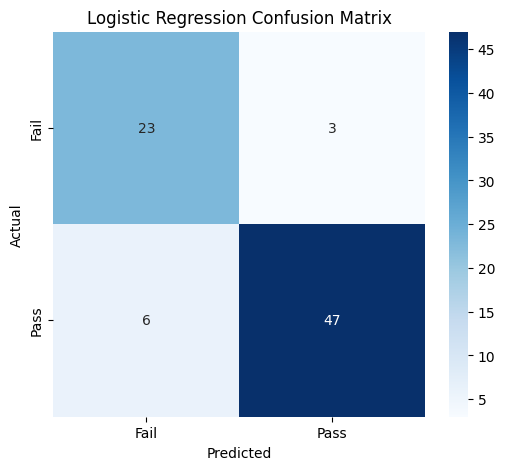

In [19]:
# CELL 11 - Logistic Regression Confusion Matrix

from sklearn.metrics import confusion_matrix

cm_log = confusion_matrix(y_test_cls, y_pred_log)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_log,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Fail", "Pass"],
    yticklabels=["Fail", "Pass"]
)

plt.title("Logistic Regression Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

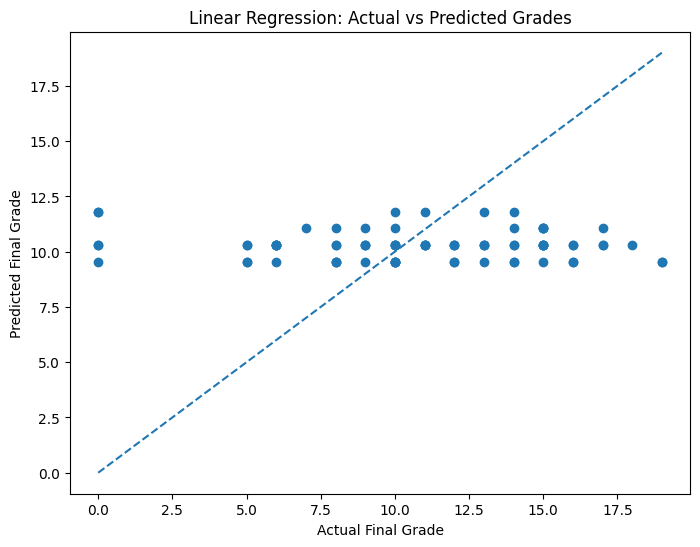

In [23]:
# Actual vs Predicted Grades - Linear Regression

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt

# X = study time, Y = final grade
X_reg = df[["studytime"]]
y_reg = df["G3"]

# Train-test split
X_reg_train, X_reg_test, y_reg_train, y_reg_test = train_test_split(
    X_reg,
    y_reg,
    test_size=0.2,
    random_state=42
)

# Create and train model
reg_model = LinearRegression()
reg_model.fit(X_reg_train, y_reg_train)

# Predictions
y_reg_pred = reg_model.predict(X_reg_test)

# Actual vs Predicted graph
plt.figure(figsize=(8, 6))

plt.scatter(y_reg_test, y_reg_pred)

plt.xlabel("Actual Final Grade")
plt.ylabel("Predicted Final Grade")
plt.title("Linear Regression: Actual vs Predicted Grades")

# Perfect prediction line
plt.plot(
    [y_reg_test.min(), y_reg_test.max()],
    [y_reg_test.min(), y_reg_test.max()],
    linestyle="--"
)

plt.show()

In [25]:

# CELL 13 — LOGISTIC REGRESSION
# Predict Pass / Fail


from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# --------------------------------------------
# Prepare classification data
# --------------------------------------------

# Features used for prediction
features = [
    "studytime",
    "failures",
    "absences",
    "G1",
    "G2"
]

X_class = df[features]

# Pass = 1, Fail = 0
y_class = (df["G3"] >= 10).astype(int)

# Train-test split
X_train_class, X_test_class, y_class_train, y_class_test = train_test_split(
    X_class,
    y_class,
    test_size=0.2,
    random_state=42,
    stratify=y_class
)

# --------------------------------------------
# Scale features for Logistic Regression
# --------------------------------------------

scaler_class = StandardScaler()

X_train_class_scaled = scaler_class.fit_transform(
    X_train_class
)

X_test_class_scaled = scaler_class.transform(
    X_test_class
)

# --------------------------------------------
# Logistic Regression
# --------------------------------------------

logistic_model = LogisticRegression(
    max_iter=1000
)

logistic_model.fit(
    X_train_class_scaled,
    y_class_train
)

# Predictions
y_logistic_pred = logistic_model.predict(
    X_test_class_scaled
)

# --------------------------------------------
# Evaluation
# --------------------------------------------

logistic_accuracy = accuracy_score(
    y_class_test,
    y_logistic_pred
)

logistic_precision = precision_score(
    y_class_test,
    y_logistic_pred,
    zero_division=0
)

logistic_recall = recall_score(
    y_class_test,
    y_logistic_pred,
    zero_division=0
)

logistic_f1 = f1_score(
    y_class_test,
    y_logistic_pred,
    zero_division=0
)

print("LOGISTIC REGRESSION RESULTS")
print("---------------------------")
print("Accuracy :", round(logistic_accuracy, 2))
print("Precision:", round(logistic_precision, 2))
print("Recall   :", round(logistic_recall, 2))
print("F1 Score :", round(logistic_f1, 2))

LOGISTIC REGRESSION RESULTS
---------------------------
Accuracy : 0.89
Precision: 0.94
Recall   : 0.89
F1 Score : 0.91


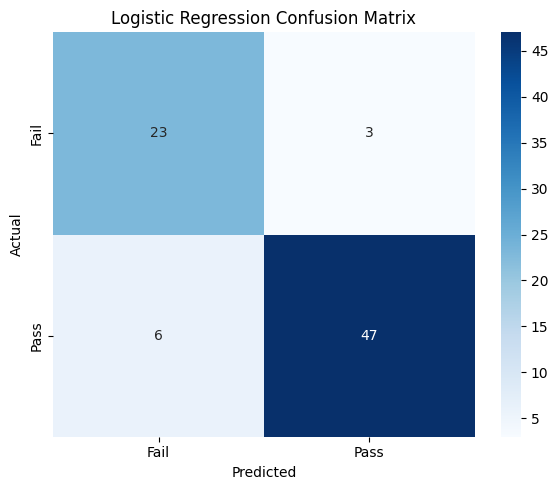

In [26]:

# CELL 14 — LOGISTIC REGRESSION CONFUSION MATRIX


cm_logistic = confusion_matrix(
    y_class_test,
    y_logistic_pred
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_logistic,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Fail", "Pass"],
    yticklabels=["Fail", "Pass"]
)

plt.title("Logistic Regression Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.tight_layout()
plt.show()

In [27]:

# CELL 15 — DECISION TREE CLASSIFIER
# Predict Pass / Fail


from sklearn.tree import DecisionTreeClassifier

# Create Decision Tree model
decision_tree = DecisionTreeClassifier(
    random_state=42,
    max_depth=5
)

# Train the model
decision_tree.fit(
    X_train_class,
    y_class_train
)

# Predictions
y_tree_pred = decision_tree.predict(
    X_test_class
)

# Evaluation
tree_accuracy = accuracy_score(
    y_class_test,
    y_tree_pred
)

tree_precision = precision_score(
    y_class_test,
    y_tree_pred,
    zero_division=0
)

tree_recall = recall_score(
    y_class_test,
    y_tree_pred,
    zero_division=0
)

tree_f1 = f1_score(
    y_class_test,
    y_tree_pred,
    zero_division=0
)

print("DECISION TREE RESULTS")
print("---------------------")
print("Accuracy :", round(tree_accuracy, 2))
print("Precision:", round(tree_precision, 2))
print("Recall   :", round(tree_recall, 2))
print("F1 Score :", round(tree_f1, 2))

DECISION TREE RESULTS
---------------------
Accuracy : 0.91
Precision: 0.96
Recall   : 0.91
F1 Score : 0.93


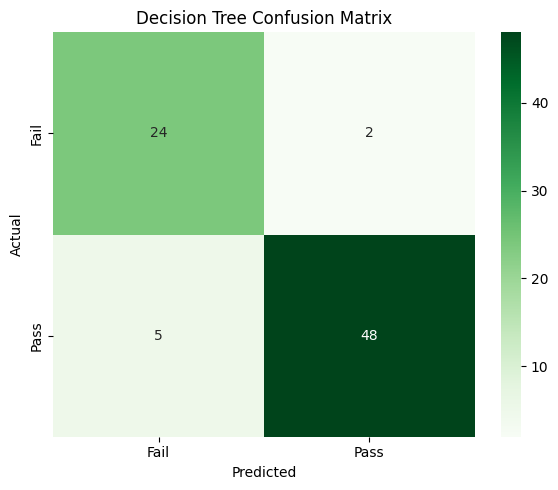

In [28]:

# CELL 16 — DECISION TREE CONFUSION MATRIX


cm_tree = confusion_matrix(
    y_class_test,
    y_tree_pred
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_tree,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["Fail", "Pass"],
    yticklabels=["Fail", "Pass"]
)

plt.title("Decision Tree Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.tight_layout()
plt.show()

In [29]:

# CELL 17 — MODEL COMPARISON


results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree"
    ],
    "Accuracy": [
        logistic_accuracy,
        tree_accuracy
    ],
    "Precision": [
        logistic_precision,
        tree_precision
    ],
    "Recall": [
        logistic_recall,
        tree_recall
    ],
    "F1 Score": [
        logistic_f1,
        tree_f1
    ]
})

print("MODEL COMPARISON")
print("================")

display(results.round(2))

MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.89,0.94,0.89,0.91
1,Decision Tree,0.91,0.96,0.91,0.93


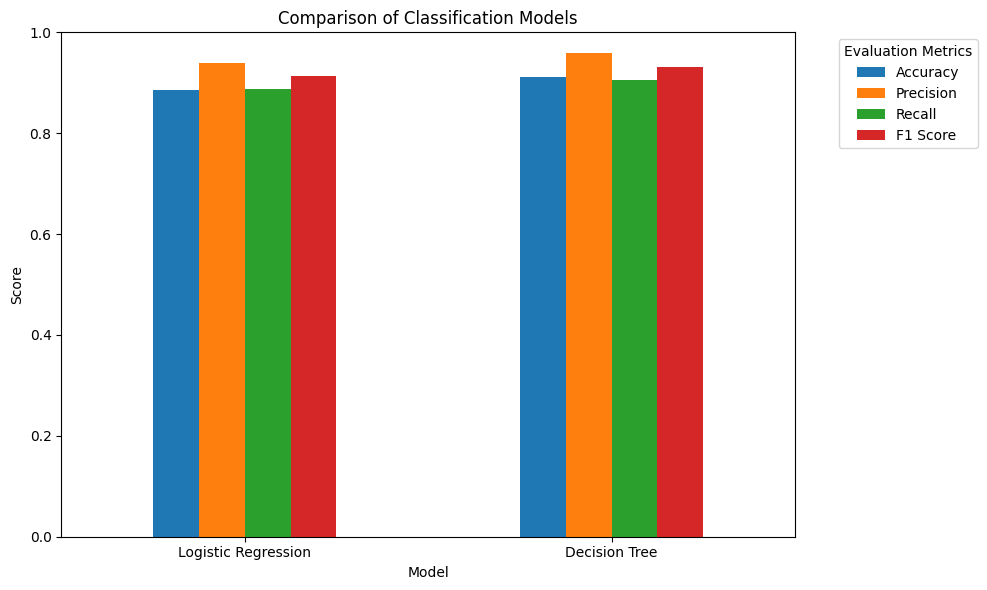

In [30]:

# CELL 18 — CLASSIFICATION MODEL COMPARISON


results_plot = results.set_index("Model")

results_plot.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Comparison of Classification Models")
plt.ylabel("Score")
plt.xlabel("Model")
plt.ylim(0, 1)

plt.xticks(rotation=0)

plt.legend(
    title="Evaluation Metrics",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

In [31]:

# CELL 19 — DECISION TREE FEATURE IMPORTANCE


feature_importance = pd.DataFrame({
    "Feature": features,
    "Importance": decision_tree.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print("DECISION TREE FEATURE IMPORTANCE")
print("================================")

display(
    feature_importance.round(4)
)

DECISION TREE FEATURE IMPORTANCE


,Feature,Importance
4,G2,0.8891
2,absences,0.0592
3,G1,0.0446
0,studytime,0.0072
1,failures,0.0000


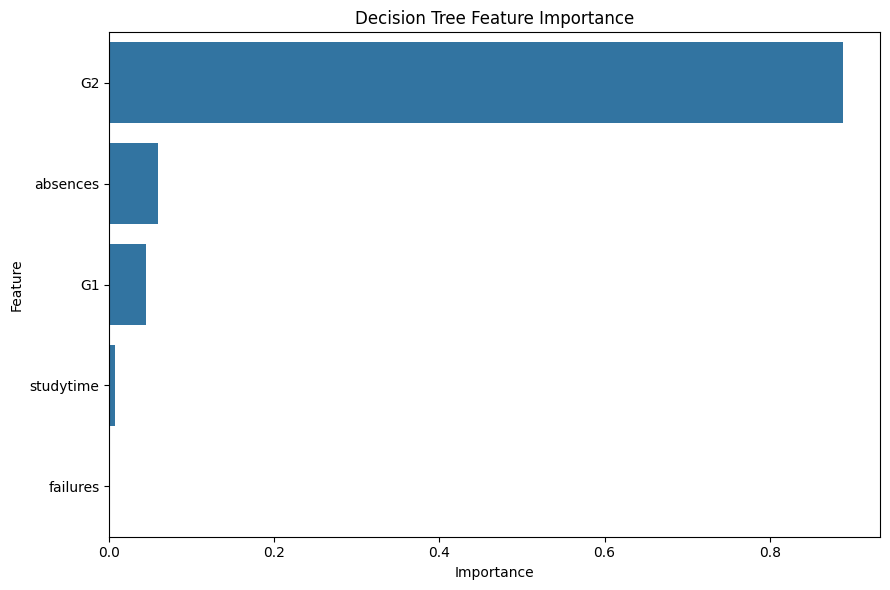

In [32]:

# FEATURE IMPORTANCE GRAPH


plt.figure(figsize=(9, 6))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)

plt.title("Decision Tree Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

In [33]:

# CELL 20 — FINAL CLASSIFICATION REPORTS

print("LOGISTIC REGRESSION CLASSIFICATION REPORT")
print("==========================================")

print(
    classification_report(
        y_class_test,
        y_logistic_pred,
        target_names=["Fail", "Pass"],
        zero_division=0
    )
)

print("\nDECISION TREE CLASSIFICATION REPORT")
print("====================================")

print(
    classification_report(
        y_class_test,
        y_tree_pred,
        target_names=["Fail", "Pass"],
        zero_division=0
    )
)

LOGISTIC REGRESSION CLASSIFICATION REPORT
              precision    recall  f1-score   support

        Fail       0.79      0.88      0.84        26
        Pass       0.94      0.89      0.91        53

    accuracy                           0.89        79
   macro avg       0.87      0.89      0.87        79
weighted avg       0.89      0.89      0.89        79


DECISION TREE CLASSIFICATION REPORT
              precision    recall  f1-score   support

        Fail       0.83      0.92      0.87        26
        Pass       0.96      0.91      0.93        53

    accuracy                           0.91        79
   macro avg       0.89      0.91      0.90        79
weighted avg       0.92      0.91      0.91        79



In [34]:

# CELL 21 — FINAL CONCLUSION

best_accuracy_model = results.loc[
    results["Accuracy"].idxmax(),
    "Model"
]

best_f1_model = results.loc[
    results["F1 Score"].idxmax(),
    "Model"
]

print("FINAL CONCLUSION")
print("================")

print(
    "The Student Performance Predictor was developed "
    "using Linear Regression, Logistic Regression, "
    "and Decision Tree models."
)

print(
    "\nLinear Regression was used to predict the "
    "student's final grade (G3)."
)

print(
    "\nLogistic Regression and Decision Tree were used "
    "to classify students as Pass or Fail."
)

print(
    f"\nBased on Accuracy, the better classification "
    f"model was: {best_accuracy_model}"
)

print(
    f"Based on F1 Score, the better classification "
    f"model was: {best_f1_model}"
)

print(
    "\nThe project demonstrates data preprocessing, "
    "feature scaling, machine learning, visualization, "
    "and model evaluation."
)

FINAL CONCLUSION
The Student Performance Predictor was developed using Linear Regression, Logistic Regression, and Decision Tree models.

Linear Regression was used to predict the student's final grade (G3).

Logistic Regression and Decision Tree were used to classify students as Pass or Fail.

Based on Accuracy, the better classification model was: Decision Tree
Based on F1 Score, the better classification model was: Decision Tree

The project demonstrates data preprocessing, feature scaling, machine learning, visualization, and model evaluation.
